**Nombre completo:** **Noriega Velazquez Jesus Manuel**

**Grupo:** **002**

**Fecha:** **14/10/2026**

---

# Actividad 9 · Ejercicios de variables aleatorias continuas
**Simulación de Sistemas (061CP048) · EC2 · Grupo 002**

Resuelva los seis ejercicios sobre la ventanilla del banco. Utilice únicamente `random`, `math` y `matplotlib`; programe las funciones de generación a mano, salvo donde se pida usar la librería. Escriba `random.seed(2026)` al inicio de cada ejercicio. Cuando se pida explicar, responda en una celda de texto con sus propias palabras.

**Entrega:** antes de la sesión del miércoles 21 de octubre de 2026, en su repositorio `simulacion-apellido-nombre`.

In [2]:
import math
import random
import matplotlib.pyplot as plt

## Ejercicio 1. Tiempo de servicio uniforme

En la ventanilla, el tiempo para atender un depósito varía de manera uniforme entre 2 y 6 minutos.

1. Programe la función `uniforme(a, b)` usando `random.random()`.
2. Genere 1 000 tiempos de servicio.
3. Calcule la media y la varianza y compárelas con los valores teóricos: media 4 y varianza 1.333.
4. Calcule qué proporción de clientes tardó más de 5 minutos y compárela con el valor teórico de 0.25.
5. Grafique el histograma de los 1 000 tiempos.

Media: 3.993 (Teórica: 4.000)
Varianza: 1.283 (Teórica: 1.333)
Proporción > 5 min: 0.233 (Teórica: 0.250)


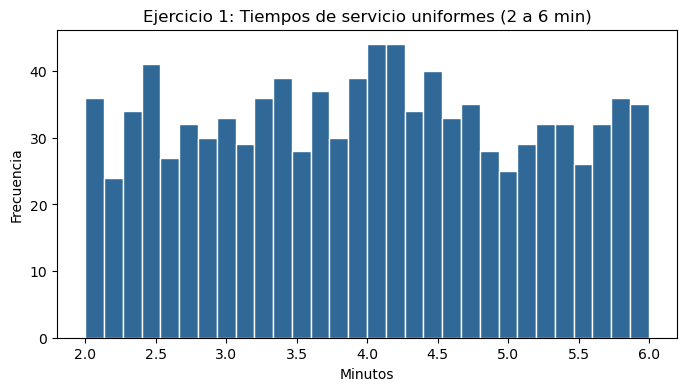

In [4]:
random.seed(2026)

def uniforme(a, b):
    return a + (b - a) * random.random()

# 2. Genere 1 000 tiempos de servicio
n = 1000
tiempos = [uniforme(2, 6) for _ in range(n)]

# 3. Calcule la media y la varianza
media = sum(tiempos) / n
varianza = sum((t - media) ** 2 for t in tiempos) / n
print(f"Media: {media:.3f} (Teórica: 4.000)")
print(f"Varianza: {varianza:.3f} (Teórica: 1.333)")

# 4. Calcule la proporción de clientes que tardó más de 5 minutos
mayores_5 = sum(1 for t in tiempos if t > 5)
proporcion = mayores_5 / n
print(f"Proporción > 5 min: {proporcion:.3f} (Teórica: 0.250)")

# 5. Grafique el histograma
plt.figure(figsize=(8, 4))
plt.hist(tiempos, bins=30, color="#306998", edgecolor="white")
plt.title("Ejercicio 1: Tiempos de servicio uniformes (2 a 6 min)")
plt.xlabel("Minutos")
plt.ylabel("Frecuencia")
plt.show()


## Ejercicio 2. Tiempo entre llegadas exponencial

En promedio llega un cliente cada 3 minutos.

1. Indique el valor de λ en clientes por minuto.
2. Programe la función `exponencial(lam)` con el método de la transformada inversa.
3. Genere 1 000 tiempos entre llegadas y compare su media con el valor teórico de 3 minutos.
4. Calcule qué proporción de clientes llegó menos de 1 minuto después del anterior y compárela con el valor teórico de 0.283.
5. Grafique el histograma y explique en dos líneas por qué tiene esa forma.

Media: 2.967 (Teórica: 3.000)
Proporción < 1 min: 0.273 (Teórica: 0.283)


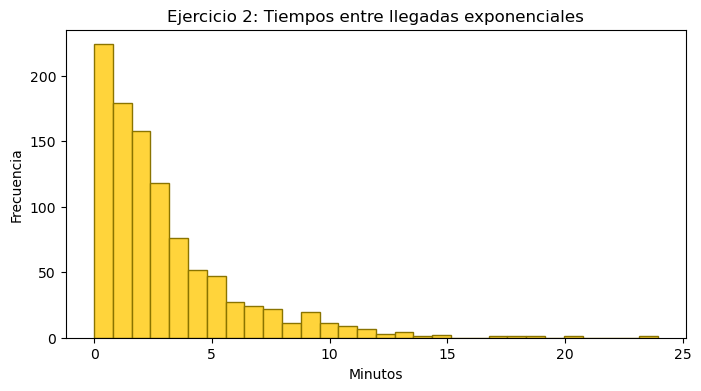

In [6]:
random.seed(2026)

# 2. Función exponencial con transformada inversa
def exponencial(lam):
    u = random.random()
    return -math.log(1 - u) / lam

lam = 1 / 3
n = 1000
llegadas = [exponencial(lam) for _ in range(n)]

# 3. Calcule y compare la media
media_llegadas = sum(llegadas) / n
print(f"Media: {media_llegadas:.3f} (Teórica: 3.000)")

# 4. Proporción que llegó en menos de 1 minuto
menores_1 = sum(1 for l in llegadas if l < 1)
proporcion_1 = menores_1 / n
print(f"Proporción < 1 min: {proporcion_1:.3f} (Teórica: 0.283)")

# 5. Histograma
plt.figure(figsize=(8, 4))
plt.hist(llegadas, bins=30, color="#FFD43B", edgecolor="#8a7400")
plt.title("Ejercicio 2: Tiempos entre llegadas exponenciales")
plt.xlabel("Minutos")
plt.ylabel("Frecuencia")
plt.show()

**Respuesta:** _El histograma tiene una forma fuertemente sesgada hacia la derecha (exponencial decreciente) porque la mayoría de los clientes tienden a llegar en intervalos cortos de tiempo, mientras que las esperas largas entre un cliente y otro son eventos mucho menos frecuentes pero posibles._

## Ejercicio 3. Comparación con la librería

1. Genere 1 000 tiempos entre llegadas con `random.expovariate`, con el mismo promedio del ejercicio 2.
2. Compare la media obtenida con la de su función del ejercicio 2 y con el valor teórico.
3. Responda: ¿`random.expovariate` recibe λ o el tiempo promedio entre llegadas? Justifique con su resultado.

In [9]:
random.seed(2026)

# 1. Generar con random.expovariate (nota: expovariate recibe lambda, no el promedio)
# Como el promedio es 3, lambda es 1/3.
datos_lib = [random.expovariate(1 / 3) for _ in range(1000)]

# 2. Media obtenida
media_lib = sum(datos_lib) / len(datos_lib)
print(f"Media con expovariate: {media_lib:.3f} (Teórica: 3.000)")

# 3. Respuesta a la pregunta

Media con expovariate: 2.967 (Teórica: 3.000)


**Respuesta:** _random.expovariate recibe el parámetro $\lambda$ (la tasa de ocurrencia, es decir, $1/3$), ya que al utilizar ese valor se obtiene un tiempo promedio de llegadas de 3 minutos, coincidiendo con la teoría y con la función programada por transformada inversa en el ejercicio anterior._

## Ejercicio 4. Trámite con distribución normal

Una apertura de cuenta tarda en promedio 8 minutos, con una desviación estándar de 1.5 minutos.

1. Programe la función `normal(mu, sigma)` con el método de Box-Müller.
2. Genere 1 000 tiempos y compare su media y su desviación estándar con los valores teóricos: 8 y 1.5.
3. Calcule qué proporción de trámites duró más de 10 minutos y compárela con el valor teórico de 0.091.
4. Genere otros 1 000 tiempos con `random.gauss(8, 1.5)` y compare su media y su desviación estándar con las de su función.
5. Responda: ¿por qué la distribución normal no es adecuada para modelar el tiempo entre llegadas?

In [18]:
random.seed(2026)

# 1. Función normal por Box-Müller
def normal(mu, sigma):
    u1 = random.random()
    u2 = random.random()
    r = math.sqrt(-2 * math.log(1 - u1))
    z = r * math.cos(2 * math.pi * u2)
    return mu + sigma * z

mu, sigma = 8, 1.5
n = 1000
tiempos_normal = [normal(mu, sigma) for _ in range(n)]

# 2. Media y desviación estándar
media_n = sum(tiempos_normal) / n
desv_n = math.sqrt(sum((t - media_n) ** 2 for t in tiempos_normal) / n)
print(f"Función propia -> Media: {media_n:.3f}, Desv: {desv_n:.3f}")

# 3. Proporción de trámites que duró más de 10 minutos
mayores_10 = sum(1 for t in tiempos_normal if t > 10)
print(f"Proporción > 10 min: {mayores_10 / n:.3f} (Teórica: 0.091)")

# 4. Comparación con random.gauss
tiempos_gauss = [random.gauss(mu, sigma) for _ in range(n)]
media_g = sum(tiempos_gauss) / n
desv_g = math.sqrt(sum((t - media_g) ** 2 for t in tiempos_gauss) / n)
print(f"random.gauss -> Media: {media_g:.3f}, Desv: {desv_g:.3f}")

Función propia -> Media: 7.914, Desv: 1.526
Proporción > 10 min: 0.084 (Teórica: 0.091)
random.gauss -> Media: 7.968, Desv: 1.393


**Respuesta:** _La distribución normal no es adecuada para modelar el tiempo entre llegadas porque permite valores negativos (lo cual no tiene sentido físico para medir el tiempo) y es simétrica, mientras que los tiempos entre llegadas reales suelen tener asimetría positiva y un límite inferior estricto en cero._

## Ejercicio 5. Simulación de la ventanilla

Simule la atención de 20 clientes en una sola ventanilla:

- El tiempo entre llegadas es exponencial, con un promedio de 3 minutos.
- El tiempo de servicio es uniforme entre 1.5 y 3.5 minutos.
- Cada cliente inicia su atención cuando llega o cuando termina el cliente anterior, lo que ocurra después.
- La espera de un cliente es su hora de inicio menos su hora de llegada.

1. Programe la función `corrida()`, que simule los 20 clientes y regrese la espera promedio.
2. Ejecute 500 corridas y reporte el promedio de las 500 esperas promedio.
3. Explique en dos líneas por qué se necesitan muchas corridas y no solo una.

In [22]:
random.seed(2026)

def corrida():
    n_clientes = 20
    # Llegadas exponenciales (promedio 3 min -> lam = 1/3)
    entre_llegadas = [exponencial(1/3) for _ in range(n_clientes)]
    # Servicio uniforme entre 1.5 y 3.5 min
    servicio = [uniforme(1.5, 3.5) for _ in range(n_clientes)]
    
    llegada = [0] * n_clientes
    acum = 0
    for i in range(n_clientes):
        acum += entre_llegadas[i]
        llegada[i] = acum
        
    inicio = [0] * n_clientes
    fin = [0] * n_clientes
    esperas = [0] * n_clientes
    
    for i in range(n_clientes):
        if i == 0:
            inicio[i] = llegada[i]
        else:
            inicio[i] = max(llegada[i], fin[i-1])
        fin[i] = inicio[i] + servicio[i]
        esperas[i] = inicio[i] - llegada[i]
        
    return sum(esperas) / n_clientes

# 2. Ejecute 500 corridas y reporte el promedio
n_corridas = 500
promedios_espera = [corrida() for _ in range(n_corridas)]
resultado_final = sum(promedios_espera) / n_corridas
print(f"Espera promedio de 500 corridas: {resultado_final:.3f} min")

Espera promedio de 500 corridas: 3.280 min


**Respuesta:** _Se necesitan muchas corridas porque el sistema de colas es estocástico; una sola corrida genera una muestra muy pequeña y sesgada por el azar inicial, mientras que el promedio de 500 corridas estabiliza el resultado y ofrece una estimación confiable del comportamiento real del banco._

## Ejercicio 6. Mismo promedio, distinta variabilidad

Repita el ejercicio 5 con un tiempo de servicio exponencial con promedio de 2.5 minutos, el mismo promedio que el servicio uniforme del ejercicio 5.

1. Ejecute 500 corridas y reporte el promedio de las esperas.
2. Compare el resultado con el del ejercicio 5. ¿La espera sube o baja?
3. Explique en tres líneas por qué cambia la espera si el servicio promedio es el mismo.

In [25]:
random.seed(2026)

def corrida_exp():
    n_clientes = 20
    entre_llegadas = [exponencial(1/3) for _ in range(n_clientes)]
    # Servicio exponencial con promedio de 2.5 min (lam = 1/2.5 = 0.4)
    servicio = [exponencial(1/2.5) for _ in range(n_clientes)]
    
    llegada = [0] * n_clientes
    acum = 0
    for i in range(n_clientes):
        acum += entre_llegadas[i]
        llegada[i] = acum
        
    inicio = [0] * n_clientes
    fin = [0] * n_clientes
    esperas = [0] * n_clientes
    
    for i in range(n_clientes):
        if i == 0:
            inicio[i] = llegada[i]
        else:
            inicio[i] = max(llegada[i], fin[i-1])
        fin[i] = inicio[i] + servicio[i]
        esperas[i] = inicio[i] - llegada[i]
        
    return sum(esperas) / n_clientes

n_corridas = 500
promedios_espera_exp = [corrida_exp() for _ in range(n_corridas)]
resultado_final_exp = sum(promedios_espera_exp) / n_corridas
print(f"Espera promedio con servicio exponencial: {resultado_final_exp:.3f} min")

Espera promedio con servicio exponencial: 4.822 min


**Respuesta:** _Al comparar con el ejercicio 5, la espera sube notablemente.   Aunque ambos modelos tienen exactamente el mismo tiempo de servicio promedio ($2.5$ minutos), la distribución exponencial posee una variabilidad y dispersión mucho mayor que la uniforme.Esto provoca que aparezcan clientes con tiempos de atención extremadamente largos de forma ocasional, saturando la fila y haciendo que los clientes posteriores acumulen tiempos de espera mucho más altos.   _